
A partir de dados históricos, pode-se usar alguma técnicas de IA para fazer uma predição de tempo de chegada.

Modelos de Regressão:

Você pode usar modelos de regressão (como Regressão Linear, Regressão de Árvore de Decisão ou Regressão de Redes Neurais) para prever o tempo de chegada com base em características como a hora do dia, a distância até a parada, condições climáticas e dados históricos de tráfego.

Redes Neurais:

Usar redes neurais, como LSTM (Long Short-Term Memory), pode ser uma boa opção para modelar dados sequenciais, especialmente se você tiver uma série temporal de dados de passagens de ônibus.

Aprendizado de Máquina Supervisionado:

Se você tiver um conjunto de dados rotulado com os tempos de chegada reais, pode treinar um modelo de aprendizado de máquina para prever os tempos de chegada futuros com base nas entradas (como horário de passagem pela câmera, distância até a parada, etc.).


1. Regressão Linear
Vantagens:

Simplicidade: É fácil de entender e interpretar. A relação entre as variáveis é linear, o que significa que você pode rapidamente ver como uma variável (como distância) afeta a outra (tempo de chegada).
Menos Dados: Funciona bem com menos dados e pode ser eficaz em cenários simples.
Desvantagens:

Limitações de Modelagem: Se a relação entre as variáveis não for linear, a regressão linear pode não capturar adequadamente os padrões, resultando em previsões imprecisas.
Sensibilidade a Outliers: É sensível a valores extremos, que podem distorcer o modelo.

2. Redes Neurais

Vantagens:

Capacidade de Modelagem Complexa: Redes neurais, especialmente as profundas, podem modelar relações não lineares complexas entre variáveis.
Flexibilidade: Podem ser usadas para diferentes tipos de dados e problemas, como séries temporais ou dados tabulares.

Desvantagens:

Necessidade de Mais Dados: Geralmente requerem uma quantidade maior de dados para treinamento eficaz e para evitar overfitting.
Complexidade: São mais difíceis de interpretar e ajustar. O treinamento pode ser demorado e requer mais recursos computacionais.
Overfitting: Se não forem bem regularizadas, podem se ajustar muito bem aos dados de treinamento e falhar em generalizar para novos dados.


3. Outros Algoritmos de Aprendizado Supervisionado (como Florestas Aleatórias, Árvores de Decisão)

Vantagens:

Interpretação: Modelos como árvores de decisão são mais interpretáveis do que redes neurais, pois mostram claramente como as decisões são tomadas.
Robustez: Podem lidar bem com dados faltantes e outliers, e não exigem que as variáveis sejam linearmente relacionadas.
Versatilidade: Florestas Aleatórias, em particular, combinam a robustez de várias árvores de decisão, melhorando a precisão e reduzindo o risco de overfitting.

Desvantagens:

Menos Transparente que Regressão Linear: Embora sejam mais interpretáveis que redes neurais, a complexidade das florestas aleatórias pode dificultar a compreensão completa do modelo.
Desempenho Variável: O desempenho pode variar com os hiperparâmetros e a aleatoriedade na amostragem de dados.

Conclusão e Recomendação

Se os dados são simples e a relação é linear: Regressão Linear pode ser uma boa escolha devido à sua simplicidade e eficiência.

Se você tem dados complexos e não lineares: Redes Neurais podem ser uma escolha poderosa, mas exigem mais dados e recursos.

Para um equilíbrio entre interpretabilidade e desempenho: Florestas Aleatórias ou Árvores de Decisão podem ser as melhores opções. Elas são eficazes em capturar relações complexas sem a necessidade de muitos dados e geralmente têm um desempenho melhor em problemas práticos.

Recomendações Finais

Teste Várias Abordagens: Muitas vezes, a melhor maneira de determinar qual modelo funcionará melhor para o seu conjunto de dados é experimentar várias abordagens e comparar seu desempenho com validação cruzada.

Hiperparâmetros: Para qualquer modelo que você escolher, não se esqueça de ajustar os hiperparâmetros para otimizar o desempenho.

Monitoramento Contínuo: À medida que você coleta mais dados e feedback sobre as previsões, você pode querer ajustar ou trocar modelos conforme necessário.


In [ ]:
# Meu código está logo abaixo, brevemente irei fazer mais algumas modificações e melhorias, conforme for necessário.

  parada_partida        hora_partida parada_chegada        hora_chegada  \
0       Parada_A 2025-05-19 07:00:00       Parada_B 2025-05-19 07:08:00   
1       Parada_A 2025-05-19 09:42:00       Parada_B 2025-05-19 10:01:00   
2       Parada_A 2025-05-19 12:14:00       Parada_B 2025-05-19 12:26:00   
3       Parada_A 2025-05-19 15:00:00       Parada_B 2025-05-19 15:09:00   
4       Parada_A 2025-05-19 17:00:00       Parada_B 2025-05-19 17:14:00   

   hora_partida_segundos  dia_semana_partida  linha_L1  linha_L2  linha_L3  \
0                  25200                   0      True     False     False   
1                  34920                   0      True     False     False   
2                  44040                   0      True     False     False   
3                  54000                   0      True     False     False   
4                  61200                   0      True     False     False   

   tempo_medio_viagem_minutos  hora_chegada_segundos  
0                        

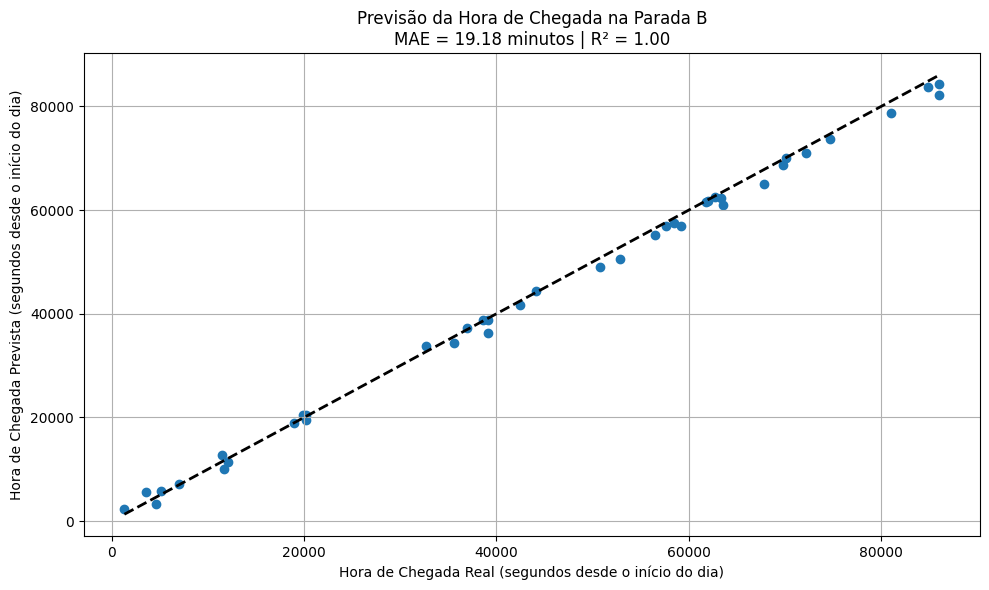

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Simular dados fictícios para duas paradas
# -----------------------------
np.random.seed(42)
n_eventos = 200
linhas = ['L1', 'L2', 'L3']
parada_partida = 'Parada_A'
parada_chegada = 'Parada_B'
base_time = pd.Timestamp("2025-05-19 07:00:00")

data_paradas = []
for linha in linhas:
    current_time_partida = base_time
    for _ in range(n_eventos // len(linhas)):
        intervalo_partida = np.random.randint(60, 181)
        tempo_viagem = np.random.randint(5, 20)
        hora_chegada = current_time_partida + pd.Timedelta(minutes=tempo_viagem)
        data_paradas.append([linha, parada_partida, current_time_partida, parada_chegada, hora_chegada])
        current_time_partida += pd.Timedelta(minutes=intervalo_partida)

df_paradas = pd.DataFrame(data_paradas, columns=['id_linha', 'parada_partida', 'hora_partida', 'parada_chegada', 'hora_chegada'])

# Engenharia de Features para prever hora_chegada
df_paradas['hora_partida_segundos'] = (df_paradas['hora_partida'].dt.hour * 3600 +
                                        df_paradas['hora_partida'].dt.minute * 60 +
                                        df_paradas['hora_partida'].dt.second)
df_paradas['dia_semana_partida'] = df_paradas['hora_partida'].dt.dayofweek
df_paradas = pd.get_dummies(df_paradas, columns=['id_linha'], prefix='linha')
tempo_medio_viagem_estimado = df_paradas['hora_chegada'] - df_paradas['hora_partida']
df_paradas['tempo_medio_viagem_minutos'] = tempo_medio_viagem_estimado.dt.total_seconds() / 60

# Variável Alvo: hora_chegada em segundos
df_paradas['hora_chegada_segundos'] = (df_paradas['hora_chegada'].dt.hour * 3600 +
                                       df_paradas['hora_chegada'].dt.minute * 60 +
                                       df_paradas['hora_chegada'].dt.second)

print(df_paradas.head())

# -----------------------------
# 4. Treinamento do modelo para prever hora_chegada
# -----------------------------
X = df_paradas.drop(columns=['parada_partida', 'hora_partida', 'parada_chegada', 'hora_chegada', 'hora_chegada_segundos'])
y = df_paradas['hora_chegada_segundos']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# Converter y_pred e y_test para horas, minutos e segundos para melhor interpretação
y_pred_time = pd.to_datetime(y_pred, unit='s', origin=pd.Timestamp('2025-05-19')).strftime('%H:%M:%S')
y_test_time = y_test.apply(lambda x: pd.to_datetime(x, unit='s', origin=pd.Timestamp('2025-05-19')).strftime('%H:%M:%S'))

# -----------------------------
# 5. Avaliação do modelo
# -----------------------------
mae = mean_absolute_error(y_test, y_pred)/60
r2 = r2_score(y_test, y_pred)

print(f"\nMAE da hora de chegada (minutos): {mae:.2f} minutoss")
print(f"R² da hora de chegada: {r2:.2f}")

# -----------------------------
# 6. Visualização (Comparação entre real e previsto)
# -----------------------------
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Hora de Chegada Real (segundos desde o início do dia)")
plt.ylabel("Hora de Chegada Prevista (segundos desde o início do dia)")
plt.title(f"Previsão da Hora de Chegada na Parada B\nMAE = {mae:.2f} minutos | R² = {r2:.2f}")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2) # Linha de referência
plt.grid(True)
plt.tight_layout()
plt.show()

  parada_partida        hora_partida parada_chegada        hora_chegada  \
0       Parada_A 2025-05-19 07:00:00       Parada_B 2025-05-19 07:08:00   
1       Parada_A 2025-05-19 09:42:00       Parada_B 2025-05-19 10:01:00   
2       Parada_A 2025-05-19 12:14:00       Parada_B 2025-05-19 12:26:00   
3       Parada_A 2025-05-19 15:00:00       Parada_B 2025-05-19 15:09:00   
4       Parada_A 2025-05-19 17:00:00       Parada_B 2025-05-19 17:14:00   

   tempo_viagem_simulado  hora_partida_segundos  dia_semana_partida  linha_L1  \
0                      8                  25200                   0      True   
1                     19                  34920                   0      True   
2                     12                  44040                   0      True   
3                      9                  54000                   0      True   
4                     14                  61200                   0      True   

   linha_L2  linha_L3  hora_chegada_segundos  
0     False    

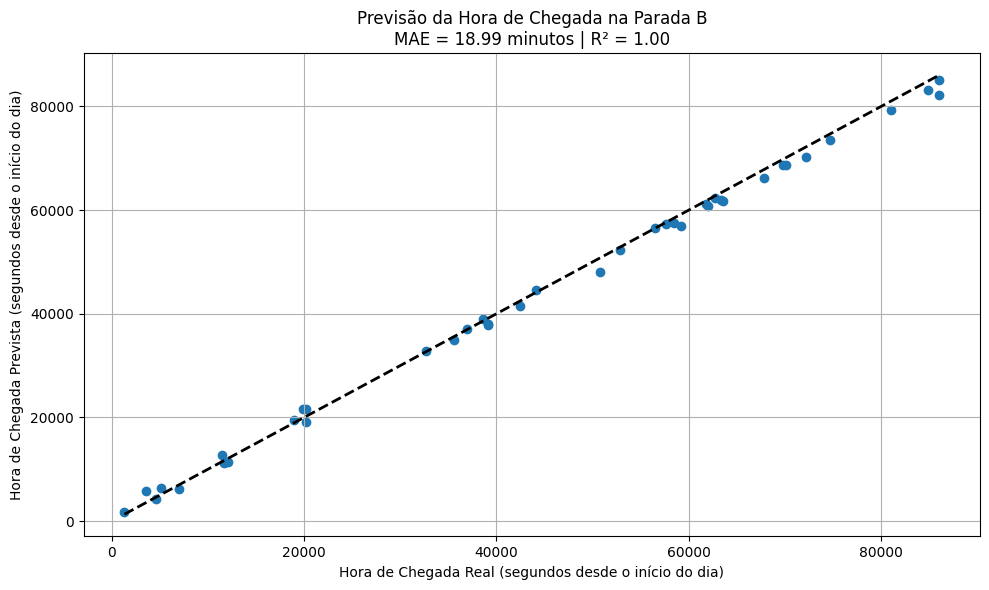

In [2]:
# Começa aqui Priscila
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Simular dados fictícios para duas paradas
# -----------------------------
np.random.seed(42)
n_eventos = 200
linhas = ['L1', 'L2', 'L3']
parada_partida = 'Parada_A'
parada_chegada = 'Parada_B'
base_time = pd.Timestamp("2025-05-19 07:00:00")

data_paradas = []
for linha in linhas:
    current_time_partida = base_time
    for _ in range(n_eventos // len(linhas)):
        intervalo_partida = np.random.randint(60, 181)
        tempo_viagem_simulado = np.random.randint(5, 20) # Renomeado para evitar confusão
        hora_chegada = current_time_partida + pd.Timedelta(minutes=tempo_viagem_simulado)
        data_paradas.append([linha, parada_partida, current_time_partida, parada_chegada, hora_chegada, tempo_viagem_simulado]) # Adicionado tempo_viagem_simulado
        current_time_partida += pd.Timedelta(minutes=intervalo_partida)

df_paradas = pd.DataFrame(data_paradas, columns=['id_linha', 'parada_partida', 'hora_partida', 'parada_chegada', 'hora_chegada', 'tempo_viagem_simulado']) # Adicionado tempo_viagem_simulado

# Engenharia de Features para prever hora_chegada
df_paradas['hora_partida_segundos'] = (df_paradas['hora_partida'].dt.hour * 3600 +
                                        df_paradas['hora_partida'].dt.minute * 60 +
                                        df_paradas['hora_partida'].dt.second)
df_paradas['dia_semana_partida'] = df_paradas['hora_partida'].dt.dayofweek
df_paradas = pd.get_dummies(df_paradas, columns=['id_linha'], prefix='linha')

# A feature 'tempo_medio_viagem_minutos' que causava vazamento será removida.
# Em vez disso, podemos usar o 'tempo_viagem_simulado' diretamente se quisermos.
# Vamos removê-la para que o modelo aprenda de forma mais orgânica.
# df_paradas['tempo_medio_viagem_minutos'] = df_paradas['tempo_viagem_simulado'] # Se quisermos incluir a *verdadeira* variação de tempo de viagem como feature

# Variável Alvo: hora_chegada em segundos
df_paradas['hora_chegada_segundos'] = (df_paradas['hora_chegada'].dt.hour * 3600 +
                                       df_paradas['hora_chegada'].dt.minute * 60 +
                                       df_paradas['hora_chegada'].dt.second)

print(df_paradas.head())

# -----------------------------
# 4. Treinamento do modelo para prever hora_chegada
# -----------------------------
# Remover 'tempo_viagem_simulado' das features se você não quiser que o modelo "saiba" o tempo exato
X = df_paradas.drop(columns=[
    'parada_partida',
    'hora_partida',
    'parada_chegada',
    'hora_chegada',
    'hora_chegada_segundos',
    'tempo_viagem_simulado' # REMOVIDO: Esta feature está muito ligada ao target.
])
y = df_paradas['hora_chegada_segundos']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

# Converter y_pred e y_test para horas, minutos e segundos para melhor interpretação
y_pred_time = pd.to_datetime(y_pred, unit='s', origin=pd.Timestamp('2025-05-19')).strftime('%H:%M:%S')
y_test_time = y_test.apply(lambda x: pd.to_datetime(x, unit='s', origin=pd.Timestamp('2025-05-19')).strftime('%H:%M:%S'))

# -----------------------------
# 5. Avaliação do modelo
# -----------------------------
mae = mean_absolute_error(y_test, y_pred) / 60 # Convertendo MAE para minutos
r2 = r2_score(y_test, y_pred)

print(f"\nMAE da hora de chegada (minutos): {mae:.2f} minutos")
print(f"R² da hora de chegada: {r2:.2f}")

# -----------------------------
# 6. Visualização (Comparação entre real e previsto)
# -----------------------------
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred)
plt.xlabel("Hora de Chegada Real (segundos desde o início do dia)")
plt.ylabel("Hora de Chegada Prevista (segundos desde o início do dia)")
plt.title(f"Previsão da Hora de Chegada na Parada B\nMAE = {mae:.2f} minutos | R² = {r2:.2f}")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2) # Linha de referência
plt.grid(True)
plt.tight_layout()
plt.show()